# 02 — OpenCV Image Manipulation

Resize, crop, rotate, flip, translate, pad, and transform images using OpenCV.

**Focus:** Practical image transformations and the parameters that control them.


In [56]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cat.jpg")
if image is None:
    raise FileNotFoundError("Could not load cat.jpg")


## 1. Resize

`cv2.resize()` changes an image’s spatial dimensions.


In [57]:
resized = cv2.resize(image, (640, 480))
print("Original:", image.shape)
print("Resized:", resized.shape)


Original: (350, 525, 3)
Resized: (480, 640, 3)


### Scale factors

`fx` and `fy` multiply the original width and height.


In [58]:
small = cv2.resize(image, None, fx=0.5, fy=0.5)
print(small.shape)


(175, 262, 3)


In [59]:
cv2.imshow("image", small)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [60]:
cv2.imshow("image", image)
cv2.waitKey(0)
cv2.destroyAllWindows()

## 2. Interpolation

Interpolation estimates pixel values when resizing. `INTER_AREA` is commonly useful for shrinking; `INTER_LINEAR` is a general default; `INTER_CUBIC` can give smoother enlargement.


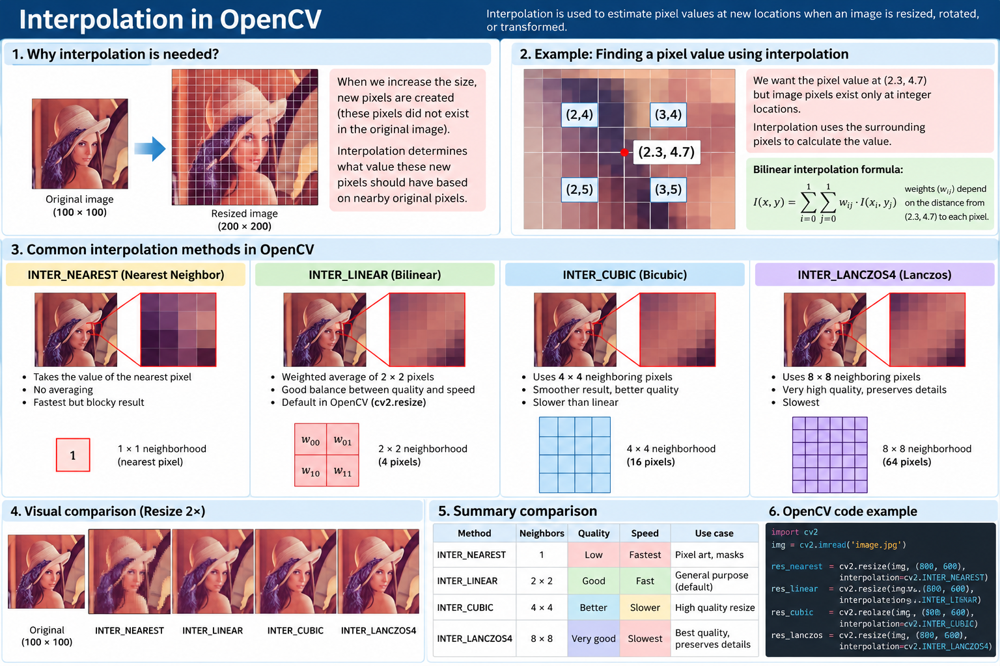

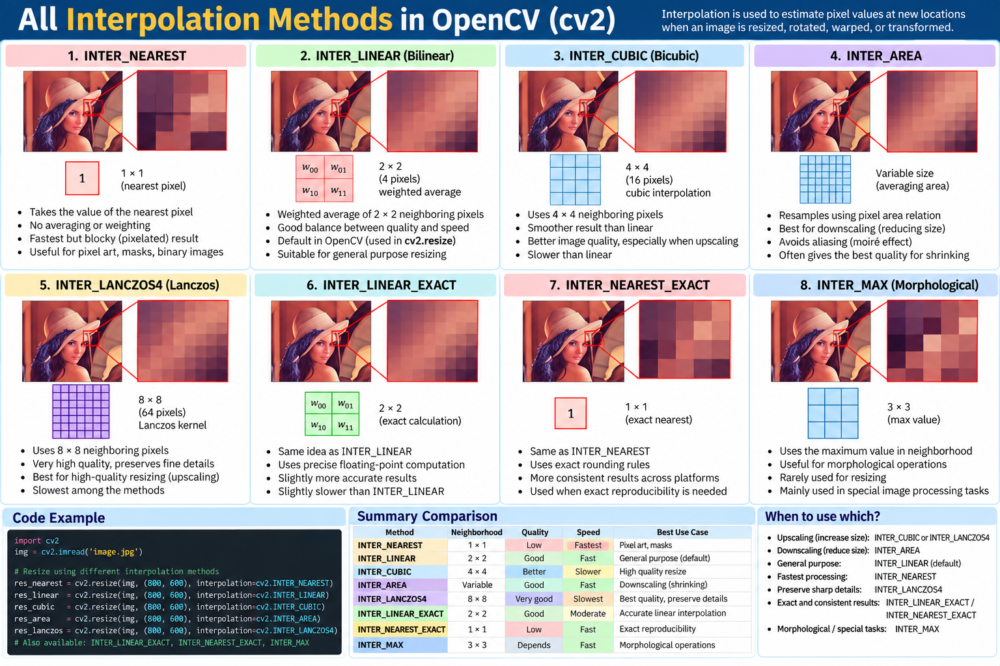

In [61]:
small = cv2.resize(image, (400, 300), interpolation=cv2.INTER_AREA)
large = cv2.resize(image, (1200, 900), interpolation=cv2.INTER_CUBIC)


In [62]:
cv2.imshow("image", small)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [63]:
cv2.imshow("image", large)
cv2.waitKey(0)
cv2.destroyAllWindows()

## 3. Aspect Ratio

$$r = \frac{W}{H}$$

Changing width and height independently can distort an image.


## if strech a 1920 x 1080 to 500 x 500 it will distort or strech

Original: 1920 × 1080

New width: 500

New height = 500 × (1080 / 1920)

           = 281.25

           ≈ 281

In [64]:
h, w = image.shape[:2]
print("Aspect ratio:", w / h)


Aspect ratio: 1.5


## 4. Crop / ROI

Cropping uses NumPy slicing: `image[y1:y2, x1:x2]`. The upper limits are exclusive.


(250, 325, 3)


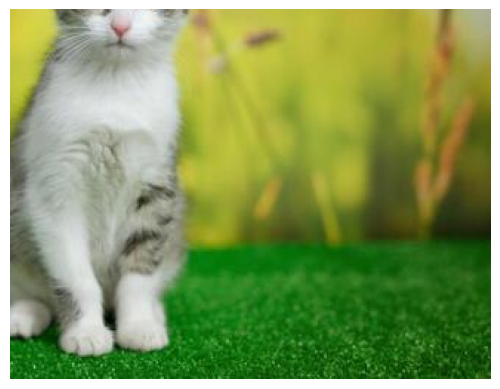

In [65]:
crop = image[100:400, 200:600]
print(crop.shape)
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


## 5. Flip

`flipCode=0` flips vertically, `1` horizontally, and `-1` along both axes.


In [66]:
horizontal = cv2.flip(image, 1)
vertical = cv2.flip(image, 0)
both = cv2.flip(image, -1)


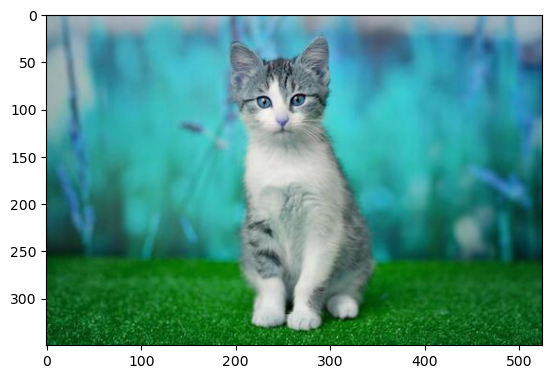

In [67]:
plt.imshow(horizontal)

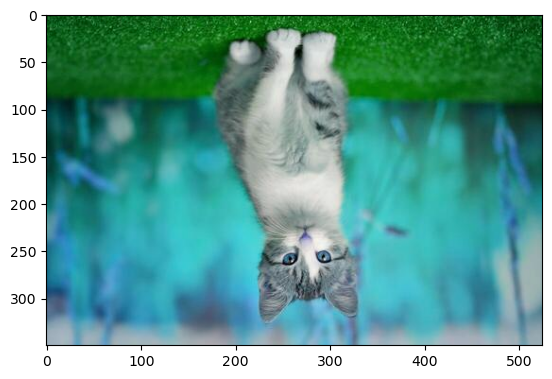

In [68]:
plt.imshow(vertical)

## 6. Rotation

`getRotationMatrix2D()` creates the rotation matrix; `warpAffine()` applies it.


[[  0.70710678   0.70710678 -47.00566338]
 [ -0.70710678   0.70710678 236.51828996]]


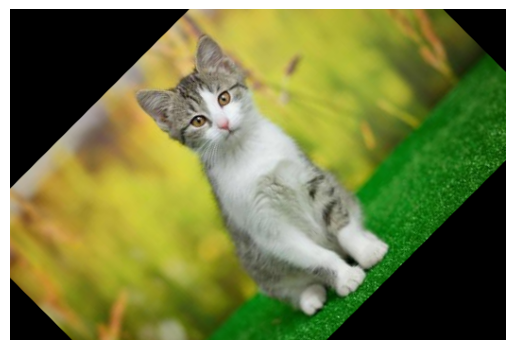

In [69]:
h, w = image.shape[:2]
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, 45, 1.0)
print(M)
rotated = cv2.warpAffine(image, M, (w, h))
plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

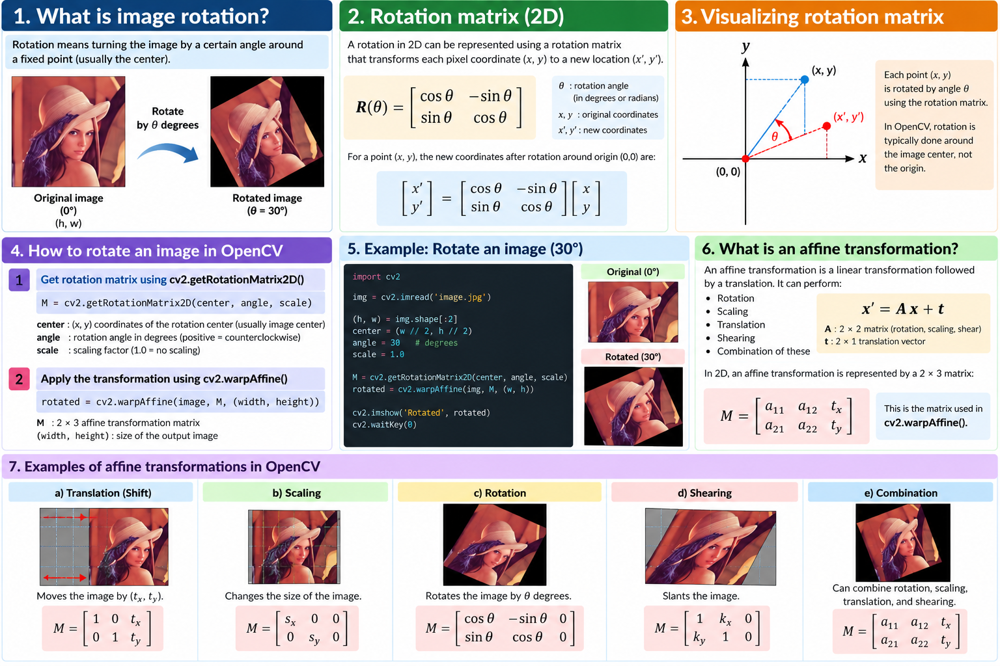

In [70]:
M = cv2.getRotationMatrix2D((w // 2, h // 2), 30, 1.0)
print(M)


[[  0.8660254    0.5        -52.39865579]
 [ -0.5          0.8660254  154.44555434]]


## 8. Translation

Translation moves every pixel by `(tx, ty)`: $$x' = x+t_x,\quad y' = y+t_y$$


In [71]:
tx, ty = 100, 50
M = np.float32([[1, 0, tx], [0, 1, ty]])
translated = cv2.warpAffine(image, M, (w, h))


## 9. Affine Transformation

Affine transformation combines translation, rotation, scaling, and shearing while preserving straight lines and parallel lines.

$$\begin{bmatrix}x\\y\end{bmatrix}=A\begin{bmatrix}x\\y\end{bmatrix}+t$$


In [72]:
M = np.float32([[1.0, 0.2, 50], [0.1, 1.0, 30]])
affine = cv2.warpAffine(image, M, (w, h))


## 10. Three-Point Affine Transform

Three non-collinear source points and their destination points define an affine mapping.


In [73]:
src = np.float32([[50, 50], [200, 50], [50, 200]])
dst = np.float32([[20, 80], [220, 40], [80, 220]])
M = cv2.getAffineTransform(src, dst)
result = cv2.warpAffine(image, M, (w, h))


## 11. Padding / Borders

`copyMakeBorder()` adds pixels around an image. Common modes are constant, replicate, reflect, and wrap.


In [74]:
bordered = cv2.copyMakeBorder(image, 50, 50, 50, 50, cv2.BORDER_CONSTANT, value=(0, 0, 0))
print("Original:", image.shape)
print("Bordered:", bordered.shape)


Original: (350, 525, 3)
Bordered: (450, 625, 3)


## 12. Perspective Transformation

Perspective transformation maps four points to four new points. It can straighten a photographed document or change viewpoint.


In [75]:
src = np.float32([[100, 100], [500, 100], [500, 400], [100, 400]])
dst = np.float32([[50, 80], [550, 50], [520, 450], [80, 420]])
H = cv2.getPerspectiveTransform(src, dst)
warped = cv2.warpPerspective(image, H, (w, h))


## 13. Perspective Mathematics

A homography is:

$$\begin{bmatrix}x'\\y'\\w'\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix}$$

Then normalize: $$x_f=x'/w',\quad y_f=y'/w'$$

The division by the third coordinate creates the perspective effect.


## 14. Function Cheat Sheet

| Function | Purpose |
|---|---|
| `cv2.resize()` | Resize |
| `cv2.flip()` | Flip |
| `cv2.getRotationMatrix2D()` | Rotation matrix |
| `cv2.warpAffine()` | Affine transform |
| `cv2.getAffineTransform()` | 3-point affine matrix |
| `cv2.getPerspectiveTransform()` | 4-point perspective matrix |
| `cv2.warpPerspective()` | Perspective transform |
| `cv2.copyMakeBorder()` | Add borders |
